# Phase 3 · Machine Learning Prediction (Q6)
**Hoàng Công Lý (`24120378`)** · Đánh giá khả năng dự đoán nhãn ý định `Y` bằng thông tin có sẵn trước khi hiển thị coupon.

## Phase 3.1 · Bài toán, Prediction Time & Leakage Audit

- **Người dùng giả định:** Hệ thống gợi ý ưu đãi trên xe xếp hạng mức độ phù hợp trước khi hiển thị coupon.
- **Kiểm soát rò rỉ dữ liệu:** Giữ **22** đặc trưng biết trước lúc gợi ý (`CONTEXT_COLS + COUPON_COLS + PROFILE_COLS + HABIT_COLS`); loại **4** cột: `Y` (target), `toCoupon_GEQ5min` (hằng số), `direction_opp` (`= 1 - direction_same`), `car` (thiếu `99,15%`).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, GroupShuffleSplit, StratifiedGroupKFold, StratifiedKFold, cross_val_score

from coupon_project.data import RAW_CSV_PATH, load_raw_data, save_table
from coupon_project.features import build_respondent_id
from coupon_project.modeling import build_pipeline, cluster_bootstrap_metric, error_breakdown, probability_bins
from coupon_project.plotting import save_figure, set_style

SEED = 42
set_style()

df = load_raw_data(RAW_CSV_PATH)
CONTEXT_COLS = ["destination", "passanger", "weather", "temperature", "time", "toCoupon_GEQ15min", "toCoupon_GEQ25min", "direction_same"]
COUPON_COLS = ["coupon", "expiration"]
PROFILE_COLS = ["gender", "age", "maritalStatus", "has_children", "education", "occupation", "income"]
HABIT_COLS = ["Bar", "CoffeeHouse", "CarryAway", "RestaurantLessThan20", "Restaurant20To50"]
FEATURE_COLS = CONTEXT_COLS + COUPON_COLS + PROFILE_COLS + HABIT_COLS
EXCLUDED = {"Y", "toCoupon_GEQ5min", "direction_opp", "car"}

assert "Y" not in FEATURE_COLS and set(FEATURE_COLS) | EXCLUDED == set(df.columns)
X, y = df[FEATURE_COLS], df["Y"]
print(f"X: {X.shape[0]:,} x {X.shape[1]} features | Y=1: {y.mean():.1%}")

X: 12,684 x 22 features | Y=1: 56.8%


## Phase 3.2 · Chia Train/Test theo người trả lời & Preprocessing Pipeline

- Không chia theo `time` (chỉ là giờ trong ngày) và không chia ngẫu nhiên theo dòng (tránh cùng người rơi vào cả train và test).
- Chia `80/20` bằng `GroupShuffleSplit` theo `567` `respondent_id` giả định; toàn bộ `SimpleImputer` + `OneHotEncoder(handle_unknown="ignore")` nằm trong `Pipeline` qua `coupon_project.modeling.build_pipeline`.

In [2]:
respondent_id = build_respondent_id(df, PROFILE_COLS + ["car"] + HABIT_COLS)
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(X, y, groups=respondent_id))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train, g_test = respondent_id.iloc[train_idx], respondent_id.iloc[test_idx]

assert len(set(g_train) & set(g_test)) == 0
display(pd.DataFrame({
    "so_dong": [len(X_train), len(X_test)],
    "so_nguoi": [g_train.nunique(), g_test.nunique()],
    "ty_le_Y1_pct": [y_train.mean() * 100, y_test.mean() * 100],
}, index=["train", "test"]).round(1))

BINARY_COLS = ["has_children", "toCoupon_GEQ15min", "toCoupon_GEQ25min", "direction_same"]
CAT_COLS = [c for c in FEATURE_COLS if c not in BINARY_COLS]

,so_dong,so_nguoi,ty_le_Y1_pct
train,10132,453,56.1
test,2552,114,59.9


## Phase 3.3 · Baseline, Tuning trên Train (5-Fold CV) & Kiểm tra rò rỉ

- So sánh **Dummy (`most_frequent`)**, **Logistic Regression**, và **Random Forest** qua `StratifiedGroupKFold(n_splits=5)` **chỉ trên tập train**.
- Chọn **ROC-AUC** làm metric chính vì không phụ thuộc ngưỡng và tránh bị đánh lừa như F1 khi lớp đa số chiếm `~57–60%`.

In [3]:
MODELS = {
    "Dummy (đa số)": (DummyClassifier(strategy="most_frequent"), {}),
    "Logistic Regression": (LogisticRegression(max_iter=2000), {"model__C": [0.001, 0.003, 0.01, 0.03, 0.1, 1.0]}),
    "Random Forest": (RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
                      {"model__max_depth": [10, 20, None], "model__min_samples_leaf": [1, 5], "model__max_features": ["sqrt", 0.2]}),
}
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"roc_auc": "roc_auc", "balanced_accuracy": "balanced_accuracy", "f1": "f1", "accuracy": "accuracy"}

searches = {}
for name, (est, grid) in MODELS.items():
    gs = GridSearchCV(build_pipeline(est, CAT_COLS, BINARY_COLS), grid, scoring=SCORING, refit="roc_auc", cv=cv, n_jobs=1)
    gs.fit(X_train, y_train, groups=g_train)
    searches[name] = gs
    print(f"{name}: best_params = {gs.best_params_}")

cv_table = pd.DataFrame({
    name: {f"{m}_mean": gs.cv_results_[f"mean_test_{m}"][gs.best_index_] for m in SCORING}
    | {f"{m}_std": gs.cv_results_[f"std_test_{m}"][gs.best_index_] for m in SCORING}
    for name, gs in searches.items()
}).T
display(cv_table.round(4))
save_table(cv_table.reset_index(names="model"), "q6_cv_summary")

selected_name = cv_table["roc_auc_mean"].idxmax()
selected_model = searches[selected_name].best_estimator_
print(f"Mô hình chọn theo CV: {selected_name}")

naive_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
leak_df = pd.DataFrame({
    name: {
        "group_cv_auc": cross_val_score(searches[name].best_estimator_, X_train, y_train, groups=g_train, cv=cv, scoring="roc_auc", n_jobs=1).mean(),
        "row_cv_auc": cross_val_score(searches[name].best_estimator_, X_train, y_train, cv=naive_cv, scoring="roc_auc", n_jobs=1).mean(),
    }
    for name in ["Logistic Regression", "Random Forest"]
}).T
leak_df["inflation"] = leak_df["row_cv_auc"] - leak_df["group_cv_auc"]
display(leak_df.round(4))

Dummy (đa số): best_params = {}


Logistic Regression: best_params = {'model__C': 0.01}


Random Forest: best_params = {'model__max_depth': 20, 'model__max_features': 0.2, 'model__min_samples_leaf': 5}


,roc_auc_mean,balanced_accuracy_mean,f1_mean,accuracy_mean,roc_auc_std,balanced_accuracy_std,f1_std,accuracy_std
Dummy (đa số),0.5000,0.5000,0.7186,0.5608,0.0000,0.0000,0.0011,0.0014
Logistic Regression,0.7218,0.6584,0.7259,0.6724,0.0111,0.0102,0.0098,0.0104
Random Forest,0.7670,0.7021,0.7592,0.7144,0.0090,0.0059,0.0087,0.0072


Mô hình chọn theo CV: Random Forest


,group_cv_auc,row_cv_auc,inflation
Logistic Regression,0.7218,0.7370,0.0152
Random Forest,0.7670,0.8101,0.0431


## Phase 3.4 · Đánh giá Test một lần & Phân tích lỗi

,cv_roc_auc,test_roc_auc,auc_ci_low,auc_ci_high,test_bal_acc,bal_ci_low,bal_ci_high,test_f1,test_acc
Dummy (đa số),0.500,0.500,0.500,0.500,0.500,0.500,0.500,0.749,0.599
Logistic Regression,0.722,0.726,0.700,0.753,0.660,0.638,0.682,0.744,0.682
Random Forest,0.767,0.781,0.755,0.807,0.706,0.682,0.732,0.775,0.724


RF - LogReg test ROC-AUC = 0.055 (95% CI: 0.037 to 0.074)


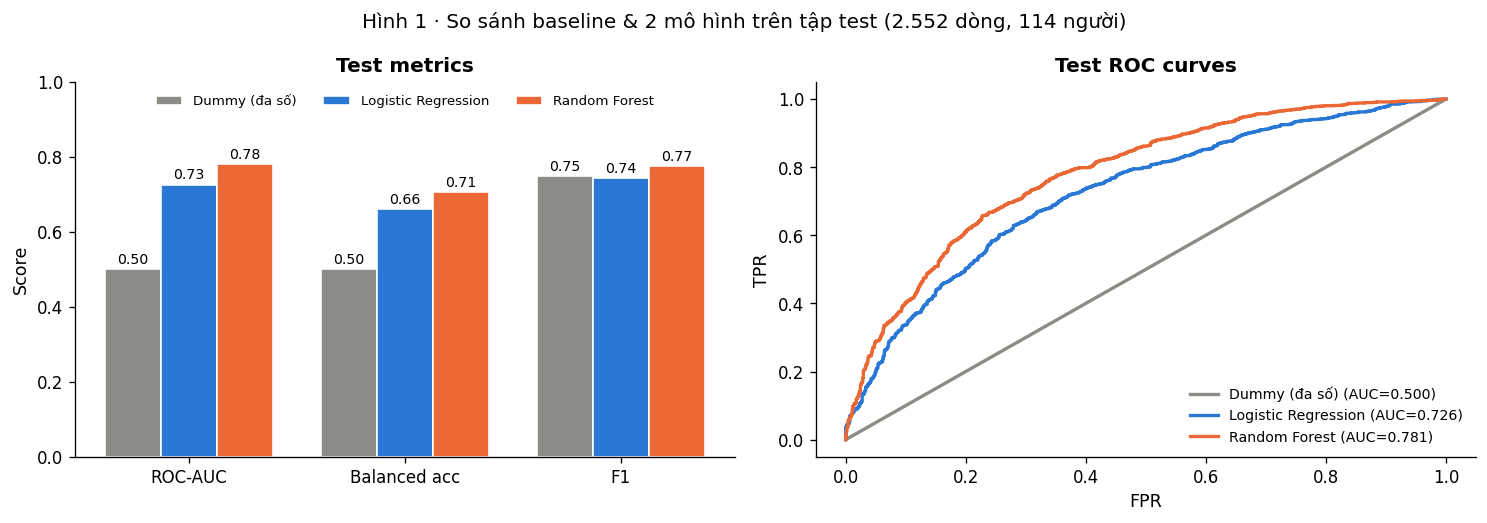

In [4]:
test_proba, test_pred, test_rows, auc_draws = {}, {}, {}, {}
for name, gs in searches.items():
    p, yhat = gs.predict_proba(X_test)[:, 1], gs.predict(X_test)
    test_proba[name], test_pred[name] = p, yhat
    auc_draws[name] = cluster_bootstrap_metric(roc_auc_score, y_test, p, g_test, seed=SEED)
    bal_draws = cluster_bootstrap_metric(balanced_accuracy_score, y_test, yhat, g_test, seed=SEED)
    test_rows[name] = {
        "cv_roc_auc": cv_table.loc[name, "roc_auc_mean"],
        "test_roc_auc": roc_auc_score(y_test, p),
        "auc_ci_low": np.percentile(auc_draws[name], 2.5),
        "auc_ci_high": np.percentile(auc_draws[name], 97.5),
        "test_bal_acc": balanced_accuracy_score(y_test, yhat),
        "bal_ci_low": np.percentile(bal_draws, 2.5),
        "bal_ci_high": np.percentile(bal_draws, 97.5),
        "test_f1": f1_score(y_test, yhat),
        "test_acc": accuracy_score(y_test, yhat),
    }
test_table = pd.DataFrame(test_rows).T
display(test_table.round(3))
save_table(test_table.reset_index(names="model"), "q6_test_metrics")

gap = auc_draws["Random Forest"] - auc_draws["Logistic Regression"]
print(f"RF - LogReg test ROC-AUC = {test_table.loc['Random Forest', 'test_roc_auc'] - test_table.loc['Logistic Regression', 'test_roc_auc']:.3f} "
      f"(95% CI: {np.percentile(gap, 2.5):.3f} to {np.percentile(gap, 97.5):.3f})")

COLORS = {"Dummy (đa số)": "#8c8b86", "Logistic Regression": "#2a78d6", "Random Forest": "#eb6834"}
METRICS = {"test_roc_auc": "ROC-AUC", "test_bal_acc": "Balanced acc", "test_f1": "F1"}

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
x = np.arange(3)
for k, name in enumerate(MODELS):
    vals = test_table.loc[name, list(METRICS)].to_numpy(float)
    pos = x + (k - 1) * 0.26
    axes[0].bar(pos, vals, width=0.26, color=COLORS[name], edgecolor="white", label=name)
    for xp, v in zip(pos, vals):
        axes[0].text(xp, v + 0.015, f"{v:.2f}", ha="center", fontsize=8.5)
axes[0].set_xticks(x, METRICS.values())
axes[0].set(ylim=(0, 1), ylabel="Score", title="Test metrics")
axes[0].legend(frameon=False, loc="upper center", ncol=3, fontsize=8)

for name in MODELS:
    fpr, tpr, _ = roc_curve(y_test, test_proba[name])
    axes[1].plot(fpr, tpr, color=COLORS[name], linewidth=2, label=f"{name} (AUC={test_table.loc[name, 'test_roc_auc']:.3f})")
axes[1].set(xlabel="FPR", ylabel="TPR", title="Test ROC curves")
axes[1].legend(frameon=False, loc="lower right", fontsize=8.5)
fig.suptitle("Hình 1 · So sánh baseline & 2 mô hình trên tập test (2.552 dòng, 114 người)")
fig.tight_layout()
save_figure(fig, "q6_fig1_model_comparison")
plt.show()

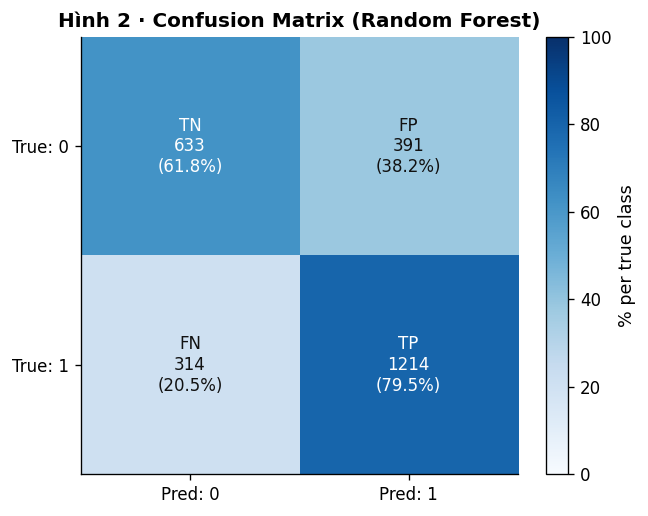

,n,true_rate,acc,FPR,FNR
coupon,,,,,
Restaurant(20-50),302,0.447,0.656,22.75,48.89
Bar,390,0.474,0.636,22.44,51.89
Coffee House,821,0.498,0.728,31.80,22.49
Restaurant(<20),562,0.760,0.769,60.00,11.48
Carry out & Take away,477,0.780,0.778,90.48,2.96


,n,true_rate,acc,FPR,FNR
passanger,,,,,
Alone,1484,0.553,0.703,31.48,28.29
Partner,193,0.565,0.715,51.19,11.01
Kid(s),198,0.586,0.747,19.51,29.31
Friend(s),677,0.713,0.765,63.40,7.45


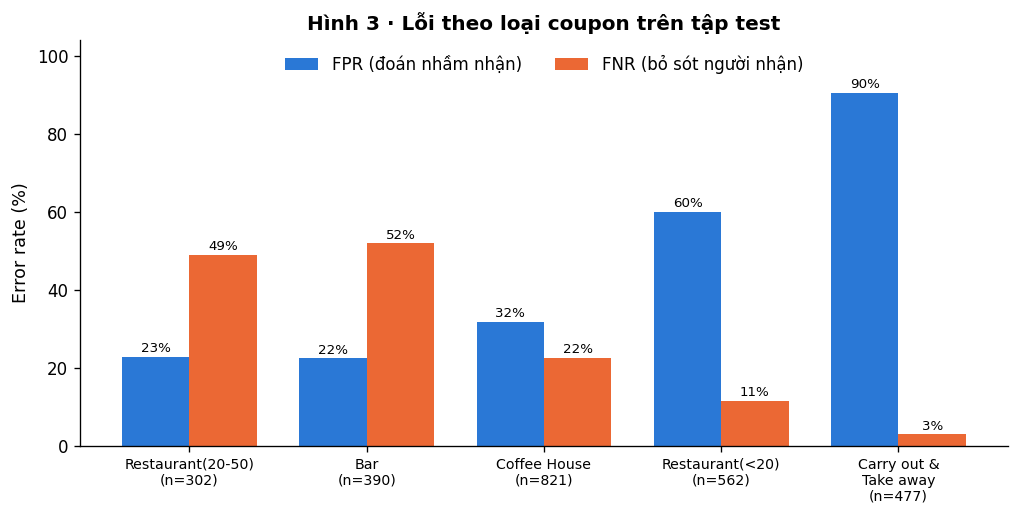

,n,mean_p,true_y,acc
p_bin,,,,
"(-0.001, 0.3]",422,0.208,0.190,0.810
"(0.3, 0.4]",251,0.354,0.410,0.590
"(0.4, 0.5]",274,0.455,0.478,0.522
"(0.5, 0.6]",340,0.552,0.571,0.571
"(0.6, 0.7]",441,0.650,0.732,0.732
"(0.7, 1.0]",824,0.797,0.846,0.846


In [5]:
sel_pred, sel_prob = test_pred[selected_name], test_proba[selected_name]
cm = confusion_matrix(y_test, sel_pred)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(figsize=(5.6, 4.4))
im = ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
names_cm = [["TN", "FP"], ["FN", "TP"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{names_cm[i][j]}\n{cm[i,j]}\n({cm_pct[i,j]:.1f}%)", ha="center", va="center", color="white" if cm_pct[i,j] >= 50 else "#111")
ax.set_xticks([0, 1], ["Pred: 0", "Pred: 1"])
ax.set_yticks([0, 1], ["True: 0", "True: 1"])
ax.set_title(f"Hình 2 · Confusion Matrix ({selected_name})")
fig.colorbar(im, ax=ax, label="% per true class")
fig.tight_layout()
save_figure(fig, "q6_fig2_confusion_matrix")
plt.show()

by_c = error_breakdown(X_test, y_test, sel_pred, sel_prob, "coupon")
by_p = error_breakdown(X_test, y_test, sel_pred, sel_prob, "passanger")
display(by_c)
display(by_p)
save_table(by_c.reset_index(), "q6_errors_by_coupon")

fig, ax = plt.subplots(figsize=(8.6, 4.4))
xc = np.arange(len(by_c))
ax.bar(xc - 0.19, by_c["FPR"], width=0.38, color="#2a78d6", label="FPR (đoán nhầm nhận)")
ax.bar(xc + 0.19, by_c["FNR"], width=0.38, color="#eb6834", label="FNR (bỏ sót người nhận)")
for xp, fpv, fnv in zip(xc, by_c["FPR"], by_c["FNR"]):
    ax.text(xp - 0.19, fpv + 1.2, f"{fpv:.0f}%", ha="center", fontsize=8)
    ax.text(xp + 0.19, fnv + 1.2, f"{fnv:.0f}%", ha="center", fontsize=8)
ax.set_xticks(xc, [f"{c.replace(' & ', ' &\n')}\n(n={n})" for c, n in zip(by_c.index, by_c["n"])], fontsize=8.5)
ax.set(ylim=(0, 104), ylabel="Error rate (%)", title="Hình 3 · Lỗi theo loại coupon trên tập test")
ax.legend(frameon=False, loc="upper center", ncol=2)
fig.tight_layout()
save_figure(fig, "q6_fig3_errors_by_coupon")
plt.show()

display(probability_bins(y_test, sel_pred, sel_prob))

## Phase 3.5 · Diễn giải mô hình, Trả lời Q6 & Hạn chế

,mean_drop_auc,std
coupon,0.1573,0.0092
CoffeeHouse,0.0569,0.0039
expiration,0.0495,0.0046
Bar,0.0168,0.0025
destination,0.0148,0.0022
time,0.0091,0.0021
passanger,0.0061,0.0016
toCoupon_GEQ15min,0.0027,0.0013
temperature,0.0019,0.0013
CarryAway,0.0015,0.0007


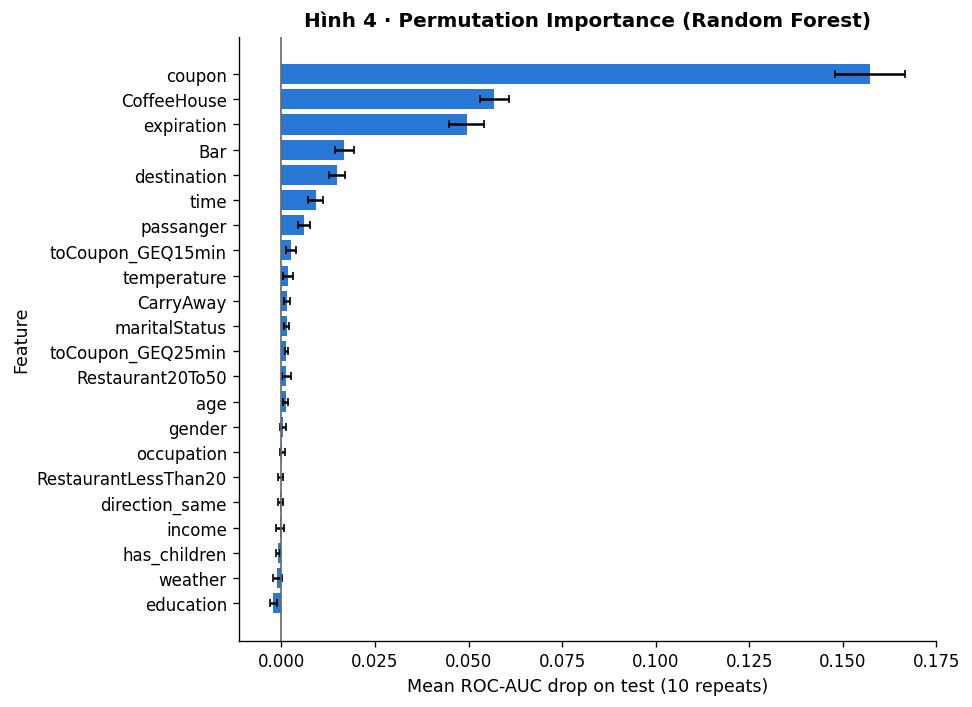

In [6]:
imp = permutation_importance(selected_model, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=1)
imp_df = pd.DataFrame({"mean_drop_auc": imp.importances_mean, "std": imp.importances_std}, index=FEATURE_COLS).sort_values("mean_drop_auc", ascending=False)
display(imp_df.head(10).round(4))
save_table(imp_df.reset_index(names="feature"), "q6_permutation_importance")

plot_imp = imp_df.iloc[::-1]
fig, ax = plt.subplots(figsize=(8.2, 6.0))
ax.barh(plot_imp.index, plot_imp["mean_drop_auc"], xerr=plot_imp["std"], color="#2a78d6", capsize=2.5)
ax.axvline(0, color="#666", linewidth=1)
ax.set(xlabel="Mean ROC-AUC drop on test (10 repeats)", ylabel="Feature", title=f"Hình 4 · Permutation Importance ({selected_name})")
fig.tight_layout()
save_figure(fig, "q6_fig4_permutation_importance")
plt.show()

### Trả lời Q6 & Hạn chế chính
1. **Có vượt baseline không?** **Có.** Trên `114` người test chưa từng thấy (`2.552` dòng), **Random Forest** đạt **ROC-AUC = 0,781** (CI 95%: `[0,755; 0,807]`), **balanced accuracy = 0,706**, **accuracy = 72,4%** (so với Dummy `0,500`, `0,500`, `59,9%` và Logistic Regression `0,726`).
2. **Giá trị sử dụng & lỗi:** Mô hình tách tốt hai đầu xác suất (`p > 0,7`: **84,6%** thật sự nhận; `p ≤ 0,3`: **19,0%** nhận) nhưng kém ở vùng `0,3–0,6` (`52–59%`) và nghiêng đoán nhận với coupon phổ biến (`Carry out` FPR **90,5%**, `Bar` FNR **51,9%**). Phù hợp để **xếp hạng ưu tiên** hơn là cắt cứng ngưỡng `0,5`.
3. **Biến dẫn dắt (không suy ra nhân quả):** `coupon` (`0,157`), `CoffeeHouse` (`0,057`), `expiration` (`0,049`), `Bar` (`0,017`); nhân khẩu học xấp xỉ `0` — nhất quán với Q3 & Q5.
4. **Hạn chế:** Dữ liệu khảo sát ý định MTurk; `respondent_id` là ID suy ra; giả định biết trước thói quen (chưa xử lý cold-start); chưa tối ưu ngưỡng theo chi phí thực tế của FP/FN.